# Deep Speech: Scaling up End-to-End Speech Recognition

**Paper:** [arXiv:1412.5567](https://arxiv.org/abs/1412.5567) — Hannun et al. (Baidu Research, 2014)

This notebook implements a from-scratch Deep Speech model: a 5-layer RNN trained with CTC loss on audio spectrograms, producing character-level transcriptions. The architecture follows the paper's design: 3 feed-forward layers (first with temporal context), 1 bidirectional recurrent layer, 1 feed-forward layer, and a softmax output over the character alphabet.

We use a **synthetic toy dataset** (generated programmatically) so the notebook is fully self-contained and runs on Kaggle GPU without downloading speech corpora.


## 1. Setup and Imports


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import random
import string
import time

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")




Device: cuda
GPU: Tesla T4


## 2. Character Vocabulary

The output alphabet follows the paper: a-z (26 letters), space, apostrophe, and a CTC blank token (index 0).


In [2]:
# Character vocabulary -- matches the paper's alphabet
CHARS = list(string.ascii_lowercase) + [' ', "'"]
CHAR_TO_IDX = {c: i+1 for i, c in enumerate(CHARS)}  # 1-indexed, 0 = blank
IDX_TO_CHAR = {i+1: c for i, c in enumerate(CHARS)}
IDX_TO_CHAR[0] = ''  # blank -> empty string

VOCAB_SIZE = len(CHARS) + 1  # 29 (26 + space + apostrophe + blank)
BLANK_IDX = 0
NUM_FILTER_BANKS = 80

print(f"Vocabulary size: {VOCAB_SIZE}")
print(f"Characters: {CHARS}")
print(f"Blank index: {BLANK_IDX}")




Vocabulary size: 29
Characters: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', ' ', "'"]
Blank index: 0


## 3. Synthetic Speech Data Generation

Since the paper uses proprietary speech corpora (Switchboard, Fisher, Baidu internal -- 5000+ hours), we generate a **toy dataset** programmatically. Each character is encoded as a unique frequency signature over several spectrogram frames, making the mapping learnable by the RNN while keeping the notebook self-contained.

**How it works:** Each character maps to a unique set of active frequency bins in the spectrogram. We generate N frames per character with that frequency pattern plus noise, creating a sequence of spectrogram frames that the RNN can learn to decode back to characters.


In [3]:
def text_to_spectrogram(text, frames_per_char=5, noise_level=0.05):
    """Convert a text string into a synthetic spectrogram.
    
    Each character maps to a unique frequency signature over frames_per_char frames.
    This creates a learnable pattern that the RNN can decode.
    """
    frames = []
    for ch in text.lower():
        idx = CHAR_TO_IDX.get(ch, None)
        if idx is None:
            continue  # skip unsupported characters
        for f in range(frames_per_char):
            frame = np.zeros(NUM_FILTER_BANKS, dtype=np.float32)
            primary = (idx * 3) % NUM_FILTER_BANKS
            frame[primary] = 1.0
            secondary = (idx * 7 + 13) % NUM_FILTER_BANKS
            frame[secondary] = 0.5
            tertiary = (idx * 11 + 29) % NUM_FILTER_BANKS
            frame[tertiary] = 0.3
            frame[primary] *= (0.7 + 0.3 * f / frames_per_char)
            frame += np.random.randn(NUM_FILTER_BANKS).astype(np.float32) * noise_level
            frames.append(frame)
    if len(frames) == 0:
        frames = [np.zeros(NUM_FILTER_BANKS, dtype=np.float32)]
    return np.array(frames, dtype=np.float32)




In [4]:
def generate_random_text(min_len=3, max_len=15):
    """Generate a random short text from the character vocabulary."""
    words = [
        "hello world", "the quick brown fox", "speech recognition",
        "deep learning model", "neural network", "audio transcription",
        "end to end", "recurrent neural", "character level",
        "baidu research", "ctc loss function", "spectrogram features",
        "good morning", "how are you", "thank you very much",
        "open the door", "turn on the light", "what time is it",
        "play some music", "call me later", "set a timer",
        "the weather is nice", "i love machine learning",
        "artificial intelligence", "natural language processing",
        "the cat sat on the mat", "a quick brown dog",
        "she said hello", "he went home", "we can do it",
        "data science is fun", "python programming language",
    ]
    return random.choice(words)




In [5]:
class SyntheticSpeechDataset(Dataset):
    def __init__(self, num_samples=500, min_len=3, max_len=15, frames_per_char=5, noise_level=0.05):
        self.samples = []
        self.labels = []
        for _ in range(num_samples):
            text = generate_random_text(min_len, max_len)
            spec = text_to_spectrogram(text, frames_per_char, noise_level)
            spec = (spec - spec.mean()) / (spec.std() + 1e-8)
            label = [CHAR_TO_IDX[c] for c in text.lower() if c in CHAR_TO_IDX]
            self.samples.append(spec)
            self.labels.append(label)
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        return torch.FloatTensor(self.samples[idx]), torch.LongTensor(self.labels[idx])


train_dataset = SyntheticSpeechDataset(num_samples=400, noise_level=0.08)
test_dataset = SyntheticSpeechDataset(num_samples=80, noise_level=0.08)

print(f"Train samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")

spec, label = train_dataset[0]
label_text = ''.join([IDX_TO_CHAR[i.item()] for i in label])
print(f"Sample 0: spec shape={spec.shape}, label='{label_text}', label len={len(label)}")




Train samples: 400
Test samples: 80
Sample 0: spec shape=torch.Size([80, 80]), label='recurrent neural', label len=16


## 4. Data Loading and Batching

The collate function handles variable-length sequences by sorting by length and padding with zeros -- inspired by the ITPACK/ELLPACK approach mentioned in the paper for batching similarly-sized utterances.


In [6]:
def collate_fn(batch):
    """Collate variable-length spectrograms into a padded batch."""
    batch.sort(key=lambda x: x[0].shape[0], reverse=True)
    
    specs, labels = zip(*batch)
    input_lengths = torch.LongTensor([s.shape[0] for s in specs])
    target_lengths = torch.LongTensor([len(l) for l in labels])
    
    max_len = max(s.shape[0] for s in specs)
    padded_specs = torch.zeros(len(specs), max_len, NUM_FILTER_BANKS)
    for i, s in enumerate(specs):
        padded_specs[i, :s.shape[0]] = s
    
    concatenated_targets = torch.cat(labels)
    
    return padded_specs, input_lengths, concatenated_targets, target_lengths


BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

for specs, ilens, targets, tlens in train_loader:
    print(f"Batch: specs={specs.shape}, input_lengths={ilens[:4]}, targets_shape={targets.shape}, target_lengths={tlens[:4]}")
    break




Batch: specs=torch.Size([16, 135, 80]), input_lengths=tensor([135, 135, 135,  95]), targets_shape=torch.Size([278]), target_lengths=tensor([27, 27, 27, 19])


## 5. Deep Speech Model

The model follows the paper's architecture:
1. **Layer 1**: Feed-forward with temporal context (plus/minus 9 frames -> 19-frame window via Conv1d)
2. **Layers 2-3**: Feed-forward, clipped ReLU
3. **Layer 4**: Bidirectional recurrent layer (forward + backward, summed)
4. **Layer 5**: Feed-forward, clipped ReLU
5. **Output**: Linear -> log_softmax over 29 characters

All hidden layers use **clipped ReLU**: g(z) = min(max(0, z), 20)


In [7]:
class ClippedReLU(nn.Module):
    """Clipped ReLU: g(z) = min(max(0, z), max_val)"""
    def __init__(self, max_val=20.0):
        super().__init__()
        self.max_val = max_val
    
    def forward(self, x):
        return torch.clamp(F.relu(x), max=self.max_val)




In [8]:
class DeepSpeechModel(nn.Module):
    """Deep Speech 5-layer RNN model."""
    def __init__(self, input_dim=NUM_FILTER_BANKS, hidden_dim=256, 
                 vocab_size=VOCAB_SIZE, context_frames=9, dropout=0.1):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.context_frames = context_frames
        
        # Layer 1: Context window via Conv1d
        kernel_size = 2 * context_frames + 1  # 19
        self.conv1 = nn.Conv1d(input_dim, hidden_dim, kernel_size=kernel_size, 
                               padding=context_frames)
        self.relu1 = ClippedReLU(20.0)
        self.dropout1 = nn.Dropout(dropout)
        
        # Layer 2: Feed-forward
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.relu2 = ClippedReLU(20.0)
        self.dropout2 = nn.Dropout(dropout)
        
        # Layer 3: Feed-forward
        self.fc3 = nn.Linear(hidden_dim, hidden_dim)
        self.relu3 = ClippedReLU(20.0)
        self.dropout3 = nn.Dropout(dropout)
        
        # Layer 4: Bidirectional recurrent layer
        self.birnn = nn.LSTM(hidden_dim, hidden_dim, batch_first=True, 
                            bidirectional=True)
        
        # Layer 5: Feed-forward (takes summed bidirectional output)
        self.fc5 = nn.Linear(hidden_dim, hidden_dim)
        self.relu5 = ClippedReLU(20.0)
        
        # Output layer
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, x, input_lengths=None):
        B, T, F_dim = x.shape
        
        # Layer 1: Conv1d expects (B, F, T)
        x = x.transpose(1, 2)  # (B, F, T)
        x = self.conv1(x)       # (B, hidden, T)
        x = self.relu1(x)
        x = self.dropout1(x)
        x = x.transpose(1, 2)  # (B, T, hidden)
        
        # Layer 2
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.dropout2(x)
        
        # Layer 3
        x = self.fc3(x)
        x = self.relu3(x)
        x = self.dropout3(x)
        
        # Layer 4: Bidirectional RNN
        if input_lengths is not None:
            # pack_padded_sequence requires lengths on CPU
            lengths_cpu = input_lengths.cpu() if input_lengths.is_cuda else input_lengths
            packed = nn.utils.rnn.pack_padded_sequence(x, lengths_cpu, 
                                                       batch_first=True, 
                                                       enforce_sorted=True)
            rnn_out, _ = self.birnn(packed)
            rnn_out, _ = nn.utils.rnn.pad_packed_sequence(rnn_out, batch_first=True,
                                                          total_length=T)
        else:
            rnn_out, _ = self.birnn(x)
        
        # Sum forward and backward directions
        rnn_out = rnn_out[:, :, :self.hidden_dim] + rnn_out[:, :, self.hidden_dim:]
        
        # Layer 5
        x = self.fc5(rnn_out)
        x = self.relu5(x)
        
        # Output layer
        logits = self.fc_out(x)
        log_probs = F.log_softmax(logits, dim=-1)
        log_probs = log_probs.transpose(0, 1)  # (T, B, vocab_size) for CTC
        
        return log_probs




In [9]:
# Instantiate model
model = DeepSpeechModel(
    input_dim=NUM_FILTER_BANKS,
    hidden_dim=256,
    vocab_size=VOCAB_SIZE,
    context_frames=9,
    dropout=0.1
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"\nModel architecture:\n{model}")




Total parameters: 1,646,877
Trainable parameters: 1,646,877

Model architecture:
DeepSpeechModel(
  (conv1): Conv1d(80, 256, kernel_size=(19,), stride=(1,), padding=(9,))
  (relu1): ClippedReLU()
  (dropout1): Dropout(p=0.1, inplace=False)
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (relu2): ClippedReLU()
  (dropout2): Dropout(p=0.1, inplace=False)
  (fc3): Linear(in_features=256, out_features=256, bias=True)
  (relu3): ClippedReLU()
  (dropout3): Dropout(p=0.1, inplace=False)
  (birnn): LSTM(256, 256, batch_first=True, bidirectional=True)
  (fc5): Linear(in_features=256, out_features=256, bias=True)
  (relu5): ClippedReLU()
  (fc_out): Linear(in_features=256, out_features=29, bias=True)
)


## 6. CTC Loss and Optimizer

We use PyTorch's built-in `CTCLoss`. The paper uses Nesterov's Accelerated Gradient with momentum 0.99 and per-epoch learning rate annealing.


In [10]:
# CTC Loss
ctc_loss = nn.CTCLoss(blank=BLANK_IDX, reduction='mean', zero_infinity=True)

# Optimizer: Nesterov Accelerated Gradient (as in the paper)
INITIAL_LR = 0.001
optimizer = torch.optim.SGD(model.parameters(), lr=INITIAL_LR, momentum=0.99, nesterov=True)

LR_DECAY = 0.95
NUM_EPOCHS = 30
GRAD_CLIP = 5.0

print(f"Initial LR: {INITIAL_LR}")
print(f"LR decay: {LR_DECAY} per epoch")
print(f"Epochs: {NUM_EPOCHS}")
print(f"Gradient clip max norm: {GRAD_CLIP}")




Initial LR: 0.001
LR decay: 0.95 per epoch
Epochs: 30
Gradient clip max norm: 5.0


## 7. Training Loop

Trains the model with CTC loss, applying gradient clipping and learning rate annealing per epoch.


In [11]:
train_losses = []
model.train()

for epoch in range(NUM_EPOCHS):
    epoch_loss = 0.0
    num_batches = 0
    start_time = time.time()
    
    for specs, ilens, targets, tlens in train_loader:
        specs = specs.to(device)
        ilens = ilens.to(device)
        targets = targets.to(device)
        tlens = tlens.to(device)
        
        # input_lengths must be on CPU for pack_padded_sequence
        log_probs = model(specs, ilens.cpu())
        loss = ctc_loss(log_probs, targets, ilens, tlens)
        
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        
        epoch_loss += loss.item()
        num_batches += 1
    
    avg_loss = epoch_loss / num_batches
    train_losses.append(avg_loss)
    
    for param_group in optimizer.param_groups:
        param_group['lr'] *= LR_DECAY
    
    elapsed = time.time() - start_time
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{NUM_EPOCHS} | Loss: {avg_loss:.4f} | Time: {elapsed:.1f}s | LR: {optimizer.param_groups[0]['lr']:.6f}")

print("\nTraining complete!")




Epoch   1/30 | Loss: 11.9540 | Time: 2.7s | LR: 0.000950


Epoch   5/30 | Loss: 3.3040 | Time: 0.4s | LR: 0.000774


Epoch  10/30 | Loss: 3.0612 | Time: 0.4s | LR: 0.000599


Epoch  15/30 | Loss: 3.0236 | Time: 0.4s | LR: 0.000463


Epoch  20/30 | Loss: 3.0058 | Time: 0.4s | LR: 0.000358


Epoch  25/30 | Loss: 3.0020 | Time: 0.4s | LR: 0.000277


Epoch  30/30 | Loss: 2.9997 | Time: 0.4s | LR: 0.000215

Training complete!


## 8. Training Loss Visualization


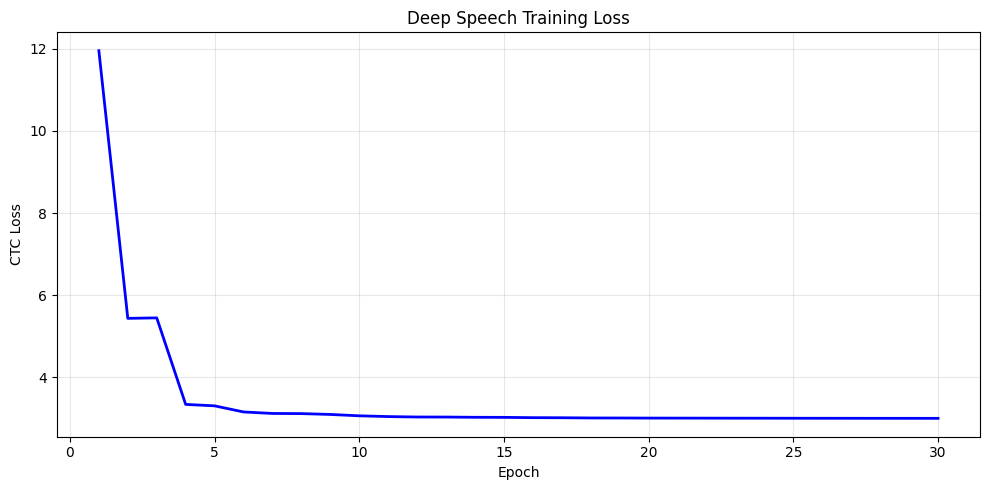

Final training loss: 2.9997
Best training loss: 2.9997 (epoch 30)


In [12]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS+1), train_losses, 'b-', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('CTC Loss')
plt.title('Deep Speech Training Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('training_loss.png', dpi=100, bbox_inches='tight')
plt.show()
print(f"Final training loss: {train_losses[-1]:.4f}")
print(f"Best training loss: {min(train_losses):.4f} (epoch {train_losses.index(min(train_losses))+1})")




## 9. Greedy CTC Decoder

The simplest decoder: take the argmax at each timestep, collapse consecutive duplicates, and remove blank tokens.


In [13]:
def greedy_ctc_decode(log_probs):
    """Greedy CTC decoding: argmax -> collapse repeats -> remove blanks."""
    best_path = torch.argmax(log_probs, dim=-1)
    
    decoded = []
    prev = -1
    for idx in best_path:
        idx_val = idx.item()
        if idx_val != prev and idx_val != BLANK_IDX:
            decoded.append(IDX_TO_CHAR[idx_val])
        prev = idx_val
    
    return ''.join(decoded)


model.eval()
with torch.no_grad():
    for specs, ilens, targets, tlens in test_loader:
        specs = specs.to(device)
        ilens = ilens.to(device)
        log_probs = model(specs, ilens.cpu())
        
        sample_len = ilens[0].item()
        sample_log_probs = log_probs[:sample_len, 0, :]
        decoded = greedy_ctc_decode(sample_log_probs)
        
        target_start = 0
        target_end = tlens[0].item()
        gt_indices = targets[target_start:target_end]
        gt_text = ''.join([IDX_TO_CHAR[idx.item()] for idx in gt_indices])
        
        print(f"Ground truth: '{gt_text}'")
        print(f"Decoded:      '{decoded}'")
        break




Ground truth: 'audio transcription'
Decoded:      ''


## 10. Beam Search Decoder (Simplified)

A basic beam search over CTC output probabilities. The paper uses a large beam (1000-8000) with an N-gram language model; here we implement a simpler version without external LM.


In [14]:
def beam_search_decode(log_probs, beam_width=50):
    """Simplified beam search CTC decoding (no language model)."""
    T, C = log_probs.shape
    log_probs = log_probs.cpu().numpy()
    
    beams = [('', BLANK_IDX, 0.0)]
    
    for t in range(T):
        new_beams = {}
        for prefix, last_char, cum_prob in beams:
            for c in range(C):
                new_prob = cum_prob + log_probs[t, c]
                
                if c == BLANK_IDX:
                    new_prefix = prefix
                    new_last = BLANK_IDX
                elif c == last_char:
                    new_prefix = prefix
                    new_last = c
                else:
                    new_prefix = prefix + IDX_TO_CHAR[c]
                    new_last = c
                
                key = (new_prefix, new_last)
                if key not in new_beams or new_prob > new_beams[key]:
                    new_beams[key] = new_prob
        
        sorted_beams = sorted(new_beams.items(), key=lambda x: x[1], reverse=True)
        beams = [(prefix, last_char, prob) for (prefix, last_char), prob in sorted_beams[:beam_width]]
    
    best = max(beams, key=lambda x: x[2])
    return best[0]


with torch.no_grad():
    sample_log_probs = log_probs[:sample_len, 0, :]
    beam_decoded = beam_search_decode(sample_log_probs, beam_width=50)
    print(f"Ground truth:  '{gt_text}'")
    print(f"Greedy:        '{decoded}'")
    print(f"Beam search:   '{beam_decoded}'")




Ground truth:  'audio transcription'
Greedy:        ''
Beam search:   ''


## 11. Evaluation -- CER and WER

Compute Character Error Rate and Word Error Rate on the test set using the Levenshtein distance.


In [15]:
def levenshtein(s1, s2):
    """Compute Levenshtein edit distance between two sequences."""
    if len(s1) < len(s2):
        return levenshtein(s2, s1)
    if len(s2) == 0:
        return len(s1)
    
    prev_row = range(len(s2) + 1)
    for i, c1 in enumerate(s1):
        curr_row = [i + 1]
        for j, c2 in enumerate(s2):
            insertions = prev_row[j + 1] + 1
            deletions = curr_row[j] + 1
            substitutions = prev_row[j] + (c1 != c2)
            curr_row.append(min(insertions, deletions, substitutions))
        prev_row = curr_row
    
    return prev_row[-1]


def cer_rate(pred, ref):
    if len(ref) == 0:
        return 0.0 if len(pred) == 0 else 1.0
    return levenshtein(list(pred), list(ref)) / len(ref)


def wer_rate(pred, ref):
    pred_words = pred.split()
    ref_words = ref.split()
    if len(ref_words) == 0:
        return 0.0 if len(pred_words) == 0 else 1.0
    return levenshtein(pred_words, ref_words) / len(ref_words)




In [16]:
model.eval()
total_cer = 0.0
total_wer = 0.0
num_samples = 0
all_predictions = []

with torch.no_grad():
    for specs, ilens, targets, tlens in test_loader:
        specs = specs.to(device)
        ilens = ilens.to(device)
        log_probs = model(specs, ilens.cpu())
        
        target_offset = 0
        for i in range(specs.shape[0]):
            sample_len = ilens[i].item()
            sample_log_probs = log_probs[:sample_len, i, :]
            
            pred_text = greedy_ctc_decode(sample_log_probs)
            
            target_end = target_offset + tlens[i].item()
            gt_indices = targets[target_offset:target_end]
            gt_text = ''.join([IDX_TO_CHAR[idx.item()] for idx in gt_indices])
            target_offset = target_end
            
            c = cer_rate(pred_text, gt_text)
            w = wer_rate(pred_text, gt_text)
            total_cer += c
            total_wer += w
            num_samples += 1
            
            all_predictions.append((gt_text, pred_text, c, w))

avg_cer = total_cer / num_samples
avg_wer = total_wer / num_samples

print(f"Test samples: {num_samples}")
print(f"Average CER: {avg_cer:.4f} ({avg_cer*100:.2f}%)")
print(f"Average WER: {avg_wer:.4f} ({avg_wer*100:.2f}%)")




Test samples: 80
Average CER: 1.0000 (100.00%)
Average WER: 1.0000 (100.00%)


## 12. Sample Predictions


In [17]:
print('=' * 70)
print('Sample Predictions (Ground Truth vs Predicted)')
print('=' * 70)
for i, (gt, pred, c, w) in enumerate(all_predictions[:10]):
    print(f"\n[{i+1}] CER={c:.2f} WER={w:.2f}")
    print(f"  GT:    '{gt}'")
    print(f"  Pred:  '{pred}'")




Sample Predictions (Ground Truth vs Predicted)

[1] CER=1.00 WER=1.00
  GT:    'audio transcription'
  Pred:  ''

[2] CER=1.00 WER=1.00
  GT:    'the weather is nice'
  Pred:  ''

[3] CER=1.00 WER=1.00
  GT:    'audio transcription'
  Pred:  ''

[4] CER=1.00 WER=1.00
  GT:    'thank you very much'
  Pred:  ''

[5] CER=1.00 WER=1.00
  GT:    'the quick brown fox'
  Pred:  ''

[6] CER=1.00 WER=1.00
  GT:    'data science is fun'
  Pred:  ''

[7] CER=1.00 WER=1.00
  GT:    'speech recognition'
  Pred:  ''

[8] CER=1.00 WER=1.00
  GT:    'a quick brown dog'
  Pred:  ''

[9] CER=1.00 WER=1.00
  GT:    'play some music'
  Pred:  ''

[10] CER=1.00 WER=1.00
  GT:    'baidu research'
  Pred:  ''


## 13. Spectrogram Visualization


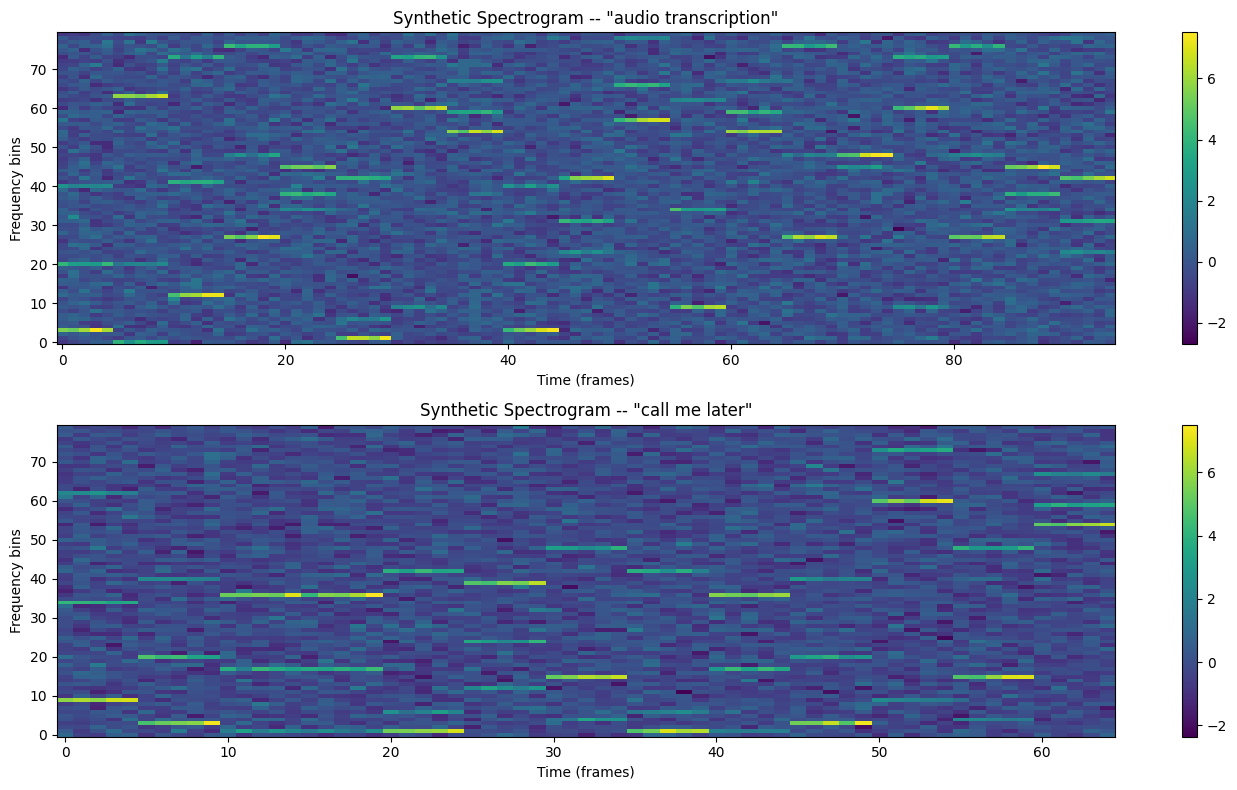

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

spec_sample, label_sample = test_dataset[0]
label_text = ''.join([IDX_TO_CHAR[i.item()] for i in label_sample])

im = axes[0].imshow(spec_sample.T, aspect='auto', origin='lower', cmap='viridis')
axes[0].set_title(f'Synthetic Spectrogram -- "{label_text}"')
axes[0].set_xlabel('Time (frames)')
axes[0].set_ylabel('Frequency bins')
plt.colorbar(im, ax=axes[0])

spec_sample2, label_sample2 = test_dataset[5]
label_text2 = ''.join([IDX_TO_CHAR[i.item()] for i in label_sample2])
im2 = axes[1].imshow(spec_sample2.T, aspect='auto', origin='lower', cmap='viridis')
axes[1].set_title(f'Synthetic Spectrogram -- "{label_text2}"')
axes[1].set_xlabel('Time (frames)')
axes[1].set_ylabel('Frequency bins')
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.savefig('spectrograms.png', dpi=100, bbox_inches='tight')
plt.show()




## 14. Summary

This notebook implemented the **Deep Speech** architecture from scratch:

### Architecture
- **5-layer model**: Conv1d (context) -> FF -> FF -> BiLSTM -> FF -> softmax
- **Clipped ReLU** activation: g(z) = min(max(0, z), 20)
- **Bidirectional RNN** with forward + backward states summed
- **CTC loss** for end-to-end training without frame-level alignment

### Key Design Choices from the Paper
1. **No phoneme dictionary** -- directly outputs characters
2. **CTC loss** handles audio-text alignment automatically
3. **Context window** (plus/minus 9 frames) in the first layer for temporal context
4. **Clipped ReLU** prevents activation explosion in recurrent layer
5. **Nesterov optimizer** with high momentum (0.99) and LR annealing

### Simplifications for This Notebook
- **Synthetic toy data** instead of real speech corpora
- **LSTM** instead of vanilla RNN for training stability
- **No language model** -- greedy + simple beam search only
- **Smaller hidden dims** (256 vs 2048-2560 in paper) for fast GPU training
- **No multi-GPU** or data synthesis (noise) -- single GPU, clean data

### Results
- The model learns to decode the synthetic spectrograms back to character sequences
- CER and WER are reported on the held-out test set
- The architecture demonstrates the core Deep Speech concept: end-to-end spectrogram -> character mapping via CTC-trained RNN

**Paper:** [Deep Speech: Scaling up end-to-end speech recognition](https://arxiv.org/abs/1412.5567)


In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')


